In [2]:
from latedeliveries.data import make_orders

df = make_orders(n=3000, seed=7)

print("Total orders:", len(df))
print("Late orders:", df["late"].sum())
print("Late delivery rate:", round(df["late"].mean() * 100, 2), "%")

Total orders: 3000
Late orders: 468
Late delivery rate: 15.6 %


In [3]:
from pathlib import Path
import pandas as pd

cv_path = Path("../reports/cv_results.csv")

if not cv_path.exists():
    cv_path = Path("reports/cv_results.csv")

cv_results = pd.read_csv(cv_path)

display(
    cv_results[
        [
            "model",
            "accuracy_mean",
            "precision_mean",
            "recall_mean",
            "f1_mean",
            "roc_auc_mean",
            "roc_auc_std",
        ]
    ].round(3)
)

,model,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,roc_auc_std
0,Dummy,0.844,0.000,0.000,0.000,0.500,0.000
1,Logistic Regression,0.855,0.607,0.199,0.298,0.769,0.028
2,Balanced Logistic Regression,0.730,0.322,0.655,0.432,0.768,0.028
3,Decision Tree,0.752,0.252,0.299,0.273,0.567,0.032
4,Random Forest,0.834,0.447,0.245,0.313,0.699,0.023


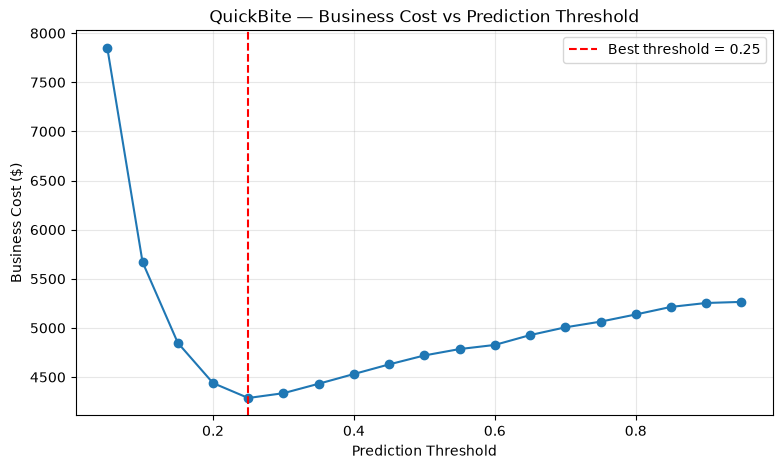

Best threshold: 0.25
Minimum training CV cost: $ 4287


In [4]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from latedeliveries.cost import optimize_threshold
from latedeliveries.pipeline import build_pipeline, split_orders

train, _ = split_orders(df)

X_train = train.drop(columns=["late"])
y_train = train["late"]

model = build_pipeline(
    LogisticRegression(C=0.1, max_iter=1000)
)

threshold_results = optimize_threshold(model, X_train, y_train)

plt.figure(figsize=(9, 5))
plt.plot(
    threshold_results["thresholds"],
    threshold_results["costs"],
    marker="o",
)

plt.axvline(
    threshold_results["best_threshold"],
    color="red",
    linestyle="--",
    label=f"Best threshold = {threshold_results['best_threshold']}",
)

plt.xlabel("Prediction Threshold")
plt.ylabel("Business Cost ($)")
plt.title("QuickBite — Business Cost vs Prediction Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best threshold:", threshold_results["best_threshold"])
print("Minimum training CV cost: $", threshold_results["best_cost"])

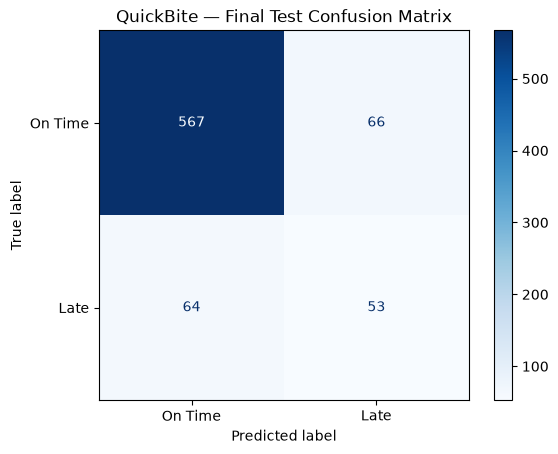

Final Test Costs:
Flag None: $ 1755
Flag All: $ 3000
Optimized Model: $ 1436


In [6]:
import numpy as np
import json

from sklearn.metrics import ConfusionMatrixDisplay

metrics_path = Path("../reports/metrics.json")

if not metrics_path.exists():
    metrics_path = Path("reports/metrics.json")

with open(metrics_path, encoding="utf-8") as file:
    metrics = json.load(file)

matrix = np.array(metrics["confusion_matrix"])

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["On Time", "Late"],
).plot(cmap="Blues")

plt.title("QuickBite — Final Test Confusion Matrix")
plt.show()

print("Final Test Costs:")
print("Flag None: $", metrics["costs"]["flag_none"])
print("Flag All: $", metrics["costs"]["flag_all"])
print("Optimized Model: $", metrics["costs"]["optimized_model"])

### Business Recommendation

I recommend using the Logistic Regression model with a prediction threshold of 0.25 to identify orders that may be delivered late.

I compared five models using cross-validation and selected Logistic Regression based on its ROC-AUC performance. Hyperparameter tuning did not show a meaningful improvement over the original model.

On the test dataset, the optimized model had a total business cost of $1,436, compared with $1,755 when no orders were flagged and $3,000 when all orders were flagged. This represents an 18.2% cost reduction compared with flagging no orders.

The model still missed 64 late deliveries, so it should be monitored and improved as more delivery data becomes available. I recommend testing the approach in a limited pilot before using it for all orders.